# Titanic Survival Project (Seaborn Titanic dataset)
## Classification Project: Comparing Several Classification Models

In [1]:
# ===================================================
# Titanic Survival Project (Seaborn Titanic dataset)
# Classification Project
# ===================================================
# 1- Required libraries (کتابخانه های مورد نیاز)
# ===================================================
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

In [2]:
# 2- Loading the dataset (بارگذاری دیتاست)
# ===================================================
titanic = sns.load_dataset("titanic")

In [3]:
# 3- Initial data exploration (شناخت اولیه داده ها)
# ===================================================
# Dataset shape (ابعاد دیتاست)
print("Dataset's Shape:", titanic.shape)
print("="*80)

# First 5 rows of the dataset (مشاهده 5 ردیف اول دیتاست)
print("\nHead of dataset:")
print(titanic.head())
print("="*80)

# General information about the columns (اطلاعات کلی ستون‌ها)
print("\nDataset Info:")
print(titanic.info())
print("="*80)

# Description of numeric columns (شرح ستون های عددی)
print("\nDescriptive Statistics of Numeric columns:")
print(titanic.describe())

Dataset's Shape: (891, 15)

Head of dataset:
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       ----

In [4]:
# 4- Exploratory Data Analysis, EDA (تحلیل اکتشافی داده ها)
# ===================================================
# 4-1- Checking missing values (بررسی داده های گمشده)
# ===================================================
print("\nMissing Values:")
print(titanic.isnull().sum())
print("\nColumns with Missing Values: ", titanic.columns[titanic.isna().any()].to_list())

# Filling missing values (پر کردن داده های گمشده)
titanic["age"] = titanic["age"].fillna(titanic["age"].median())
titanic["embarked"] = titanic["embarked"].fillna(titanic["embarked"].mode()[0])
titanic["embark_town"] = titanic["embark_town"].fillna(titanic["embark_town"].mode()[0])
titanic = titanic.drop(columns=["deck"])   # Too many missing values (تعداد زیاد داده گمشده)
print("="*80)

print("\nMissing Values After Cleaning:")
print(titanic.isnull().sum())


Missing Values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Columns with Missing Values:  ['age', 'embarked', 'deck', 'embark_town']

Missing Values After Cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


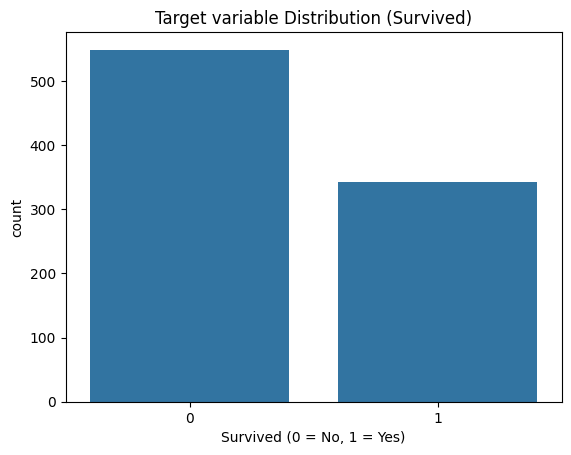


Value Percentages for survived:
survived
0    62
1    38
Name: proportion, dtype: int64


In [5]:
# 4-2- Target variable distribution, survived (توزیع متغیر هدف)
# ===================================================
plt.figure()
sns.countplot(x='survived', data=titanic)
plt.title("Target variable Distribution (Survived)")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.show()

print("\nValue Percentages for survived:")
print(np.round(titanic["survived"].value_counts(normalize=True) * 100, 0).astype(int))
print("="*80)

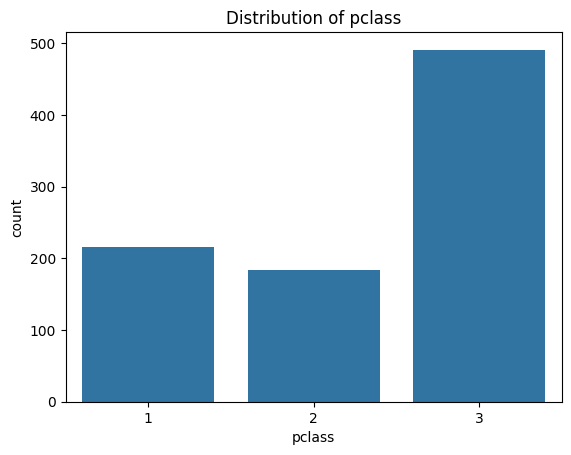


Value Counts for pclass:
pclass
3    491
1    216
2    184
Name: count, dtype: int64


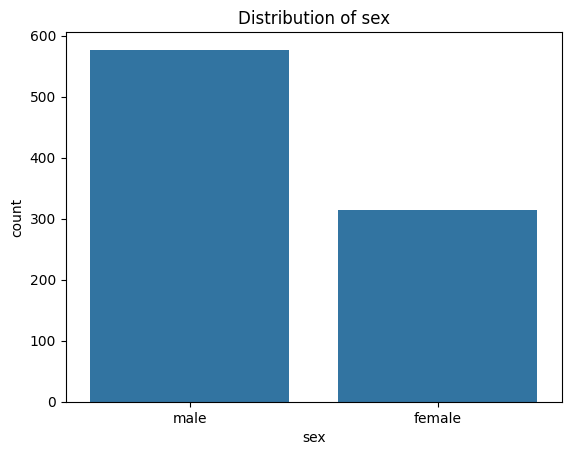


Value Counts for sex:
sex
male      577
female    314
Name: count, dtype: int64


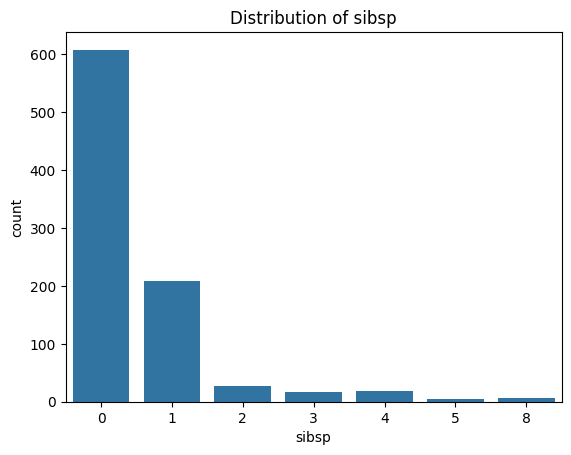


Value Counts for sibsp:
sibsp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64


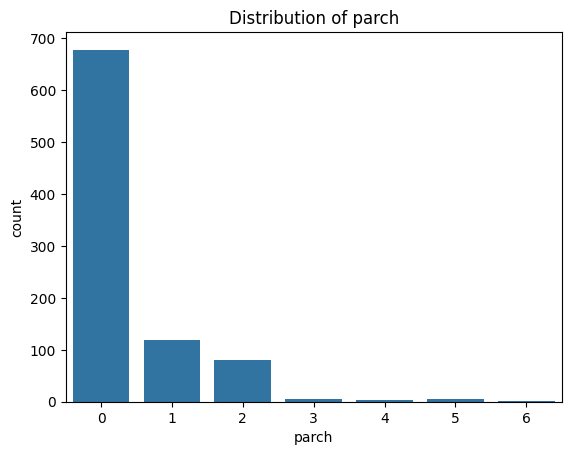


Value Counts for parch:
parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64


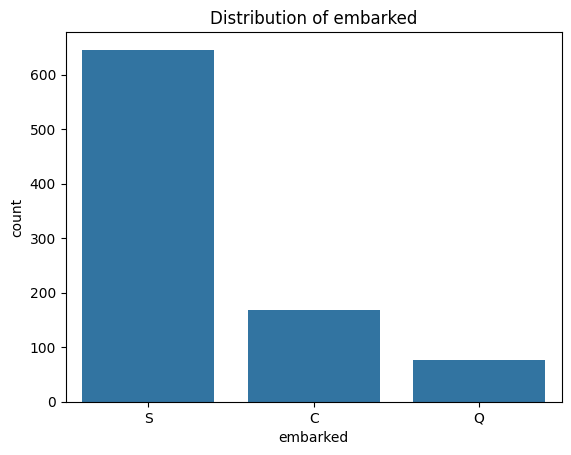


Value Counts for embarked:
embarked
S    646
C    168
Q     77
Name: count, dtype: int64


In [6]:
# 4-3- Univariate Analysis (تحلیل تک متغیره)
# ===================================================
# 4-3-1- Categorical variables analysis (تحلیل متغیرهای دسته ای)
# ===================================================
categorical_columns = ["pclass", "sex", "sibsp", "parch", "embarked"]

for col in categorical_columns:
    plt.figure()
    ax = sns.countplot(x=col, data=titanic)
    plt.title(f"Distribution of {col}")
    plt.show()

    print(f"\nValue Counts for {col}:")
    print(titanic[col].value_counts())
    print("="*80)

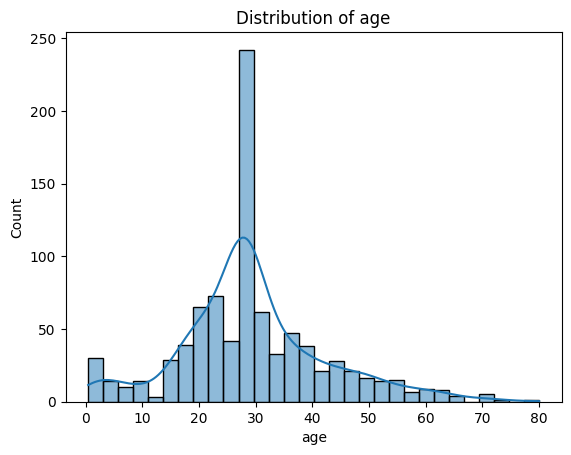


Summary Statistics for age:
count    891.00
mean      29.36
std       13.02
min        0.42
25%       22.00
50%       28.00
75%       35.00
max       80.00
Name: age, dtype: float64


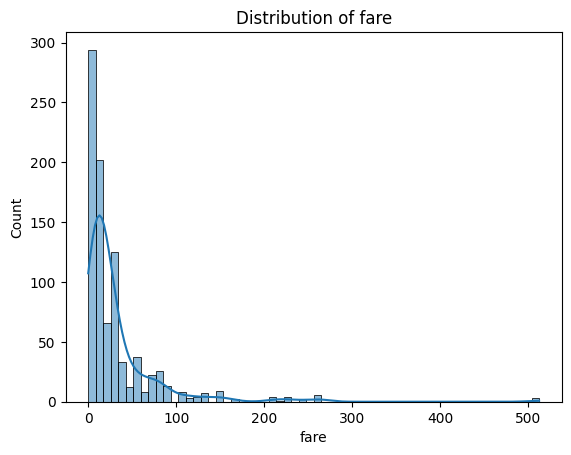


Summary Statistics for fare:
count    891.00
mean      32.20
std       49.69
min        0.00
25%        7.91
50%       14.45
75%       31.00
max      512.33
Name: fare, dtype: float64


In [7]:
# 4-3-2- Numerical variables analysis (تحلیل متغیرهای عددی)
# ===================================================
numerical_columns = ["age", "fare"]

for col in numerical_columns:
    plt.figure()
    sns.histplot(x=col, data=titanic, kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

    print(f"\nSummary Statistics for {col}:")
    print(titanic[col].describe().round(2))
    print("="*80)

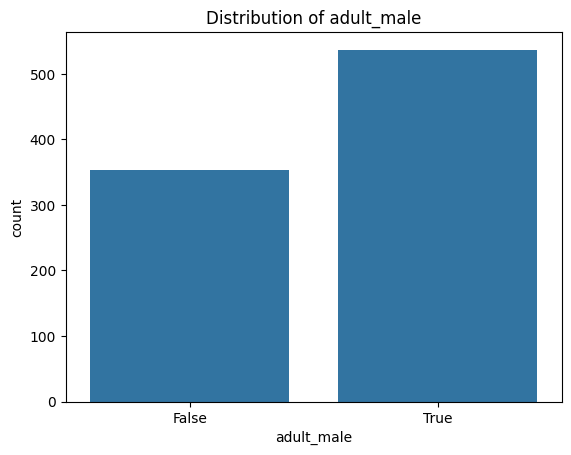


Value Counts for adult_male:
adult_male
True     537
False    354
Name: count, dtype: int64


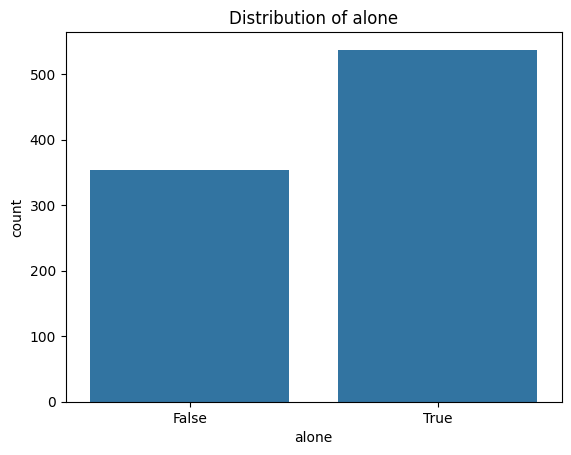


Value Counts for alone:
alone
True     537
False    354
Name: count, dtype: int64


In [8]:
# 4-3-3- Boolean variables analysis (تحلیل متغیرهای بولی)
# ===================================================
boolean_columns = ["adult_male", "alone"]

for col in boolean_columns:
    plt.figure()
    ax = sns.countplot(x=col, data=titanic)
    plt.title(f"Distribution of {col}")
    plt.show()

    print(f"\nValue Counts for {col}:")
    print(titanic[col].value_counts())
    print("="*80)

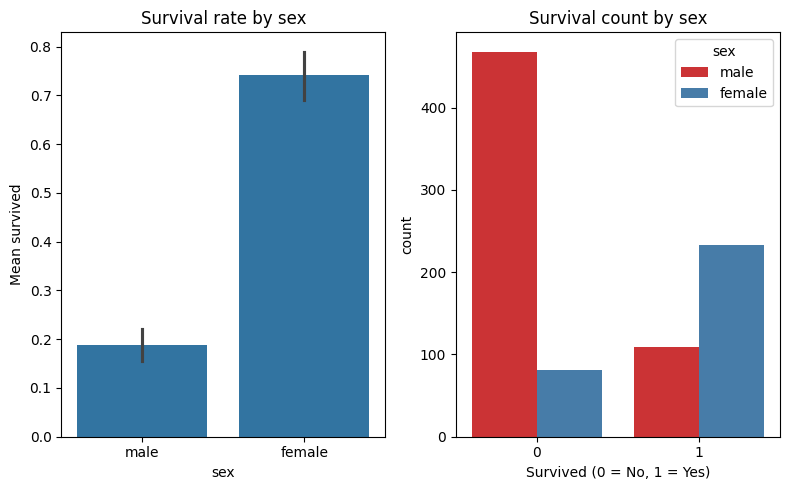

sex
female    0.74
male      0.19
Name: survived, dtype: float64

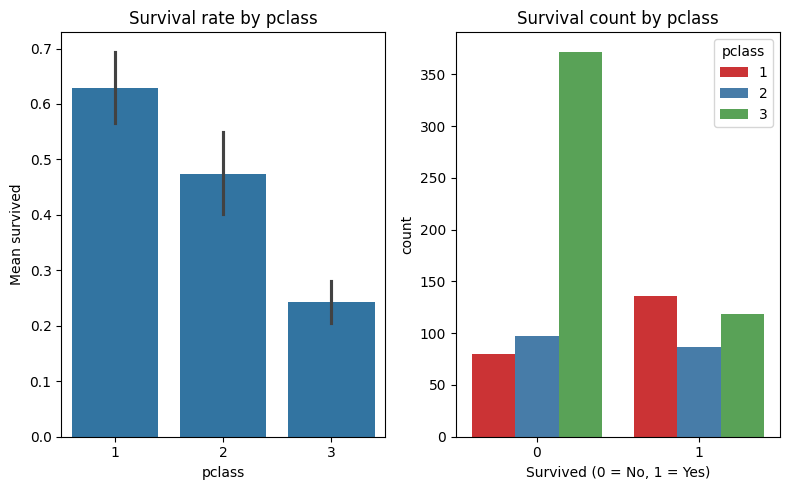

pclass
1    0.63
2    0.47
3    0.24
Name: survived, dtype: float64

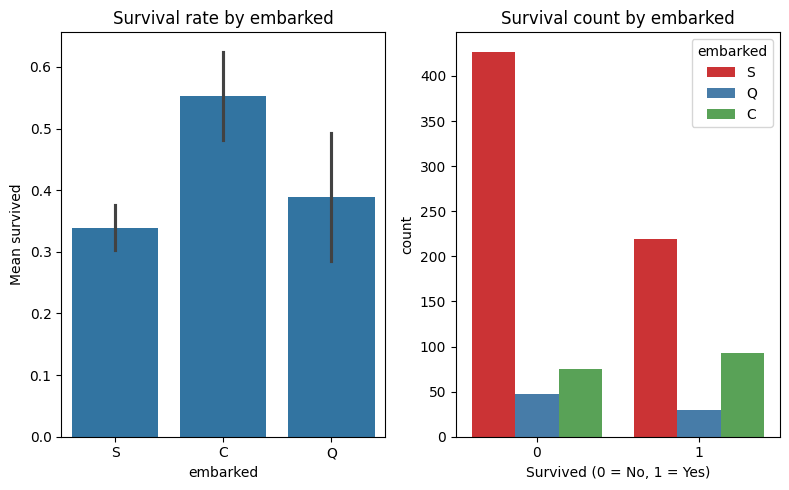

embarked
C    0.55
Q    0.39
S    0.34
Name: survived, dtype: float64

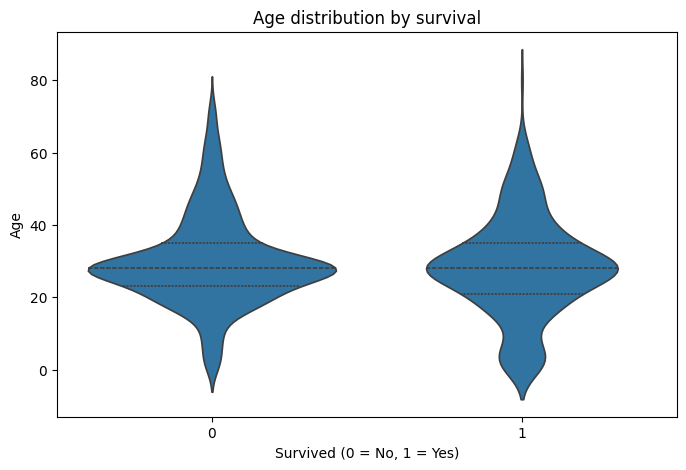

,count,mean,std,min,25%,50%,75%,max
survived,,,,,,,,
0,549.0,30.03,12.50,1.00,23.0,28.0,35.0,74.0
1,342.0,28.29,13.76,0.42,21.0,28.0,35.0,80.0


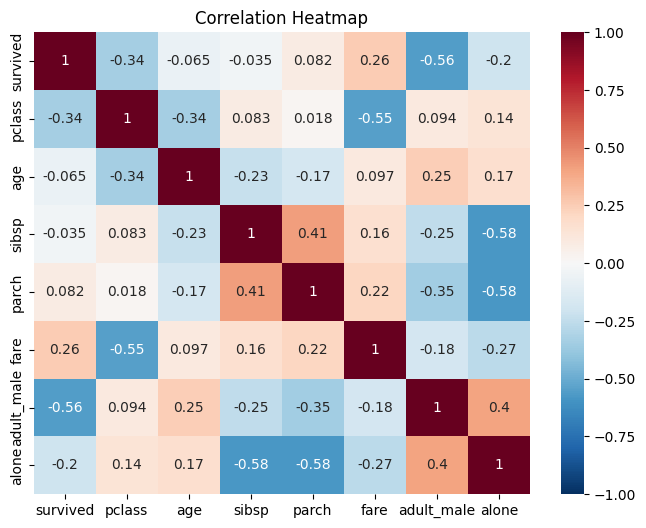

In [9]:
# 4-4- Bivariate Analysis (تحلیل دو متغیره)
# ===================================================
# survived & sex
plt.figure(figsize=(8, 5))
plt.subplot(1,2,1)
sns.barplot(data=titanic, x='sex', y='survived', estimator=np.mean)
plt.title("Survival rate by sex")
plt.xlabel("sex")
plt.ylabel("Mean survived")

plt.subplot(1,2,2)
sns.countplot(data=titanic, x='survived', hue='sex', palette="Set1")
plt.title("Survival count by sex")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.tight_layout()
plt.show()

survival_by_sex = titanic.groupby("sex")["survived"].mean().round(2).sort_values(ascending=False)
display(survival_by_sex)
print("="*80)

# survived & pclass
plt.figure(figsize=(8, 5))
plt.subplot(1,2,1)
ax = sns.barplot(data=titanic, x='pclass', y='survived', estimator=np.mean)
ax.set_title("Survival rate by pclass")
ax.set_xlabel("pclass")
ax.set_ylabel("Mean survived")

plt.subplot(1,2,2)
sns.countplot(data=titanic, x='survived', hue='pclass', palette="Set1")
plt.title("Survival count by pclass")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.tight_layout()
plt.show()

survival_by_pclass = titanic.groupby("pclass")["survived"].mean().round(2).sort_values(ascending=False)
display(survival_by_pclass)
print("="*80)

# survived & embarked
plt.figure(figsize=(8, 5))
plt.subplot(1,2,1)
ax = sns.barplot(data=titanic, x='embarked', y='survived', estimator=np.mean)
ax.set_title("Survival rate by embarked")
ax.set_xlabel("embarked")
ax.set_ylabel("Mean survived")

plt.subplot(1,2,2)
sns.countplot(data=titanic, x='survived', hue='embarked', palette="Set1")
plt.title("Survival count by embarked")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.tight_layout()
plt.show()

survival_by_embarked = titanic.groupby("embarked")["survived"].mean().round(2).sort_values(ascending=False)
display(survival_by_embarked)
print("="*80)

# survived & age
plt.figure(figsize=(8, 5))
ax = sns.violinplot(data=titanic, x='survived', y='age', inner="quartile")
ax.set_title("Age distribution by survival")
ax.set_xlabel("Survived (0 = No, 1 = Yes)")
ax.set_ylabel("Age")
plt.show()

survival_by_age = titanic.groupby("survived")["age"].describe().round(2)
display(survival_by_age)
print("="*80)

# Correlation Heatmap of numeric features (نمودار همبستگی ویژگی های عددی)
plt.figure(figsize=(8, 6))
sns.heatmap(titanic.corr(numeric_only=True), annot=True, cmap='RdBu_r', vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

In [10]:
# 5- Preprocessing & Feature Engineering (پیش پردازش و مهندسی ویژگی)
# ===================================================
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# 5-1- Dropping unnecessary columns (حذف ستون های غیر ضروری)
# ===================================================
columns_to_drop = ["class", "who", "adult_male", "embark_town", "alive", "alone"]
titanic_main_columns = titanic.drop(columns=columns_to_drop)
print("titanic main columns info:\n")
print(titanic_main_columns.info())
print("="*80)

X = titanic_main_columns.drop(columns="survived")
y = titanic_main_columns["survived"]
used_features = X.columns.to_list()
print("Used Features: ", used_features)
print("\nX shape:", X.shape, "\ty shape:", y.shape)
print("="*80)

titanic main columns info:

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    str    
 3   age       891 non-null    float64
 4   sibsp     891 non-null    int64  
 5   parch     891 non-null    int64  
 6   fare      891 non-null    float64
 7   embarked  891 non-null    str    
dtypes: float64(2), int64(4), str(2)
memory usage: 55.8 KB
None
Used Features:  ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']

X shape: (891, 7) 	y shape: (891,)


In [11]:
# 5-2- Splitting train/test data (تقسیم داده های آموزشی و آزمایشی)
# ===================================================
# The split is done BEFORE scaling so that the test data does not influence the scaler/encoder
# (تقسیم قبل از استانداردسازی انجام می شود تا داده های تست روی مقیاس دهنده تاثیر نگذارند)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("X_train shape:", X_train.shape, "y_train shape:", y_train.shape,
      "\nX_test shape:", X_test.shape, "\ty_test shape:", y_test.shape)
print("="*80)

X_train shape: (712, 7) y_train shape: (712,) 
X_test shape: (179, 7) 	y_test shape: (179,)


In [12]:
# 5-3- Feature scaling and encoding (استانداردسازی و کدگذاری فیچرها)
# ===================================================
# Identify numerical and categorical columns (شناسایی ستون های عددی و دسته ای)
numerical_cols = ["pclass", "age", "sibsp", "parch", "fare"]
categorical_cols = ["sex", "embarked"]

# Create transformers (ساخت تبدیل کننده ها)
numerical_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)], remainder="drop")

# Fit on training data only, then transform both sets
# (فقط روی داده آموزشی آموزش می بینند، سپس هر دو مجموعه تبدیل می شوند)
X_train_scaled = pd.DataFrame(preprocessor.fit_transform(X_train),
                              columns=preprocessor.get_feature_names_out(), index=X_train.index)
X_test_scaled = pd.DataFrame(preprocessor.transform(X_test),
                             columns=preprocessor.get_feature_names_out(), index=X_test.index)

print(X_train_scaled.head())
print("="*80)
print("X_train_scaled shape:", X_train_scaled.shape, "\tX_test_scaled shape:", X_test_scaled.shape)
print("="*80)

     num__pclass  num__age  num__sibsp  num__parch  num__fare  \
692     0.829568 -0.112078   -0.465084   -0.466183   0.513812   
481    -0.370945 -0.112078   -0.465084   -0.466183  -0.662563   
527    -1.571457 -0.112078   -0.465084   -0.466183   3.955399   
855     0.829568 -0.879807   -0.465084    0.727782  -0.467874   
801    -0.370945  0.118241    0.478335    0.727782  -0.115977   

     cat__sex_female  cat__sex_male  cat__embarked_C  cat__embarked_Q  \
692              0.0            1.0              0.0              0.0   
481              0.0            1.0              0.0              0.0   
527              0.0            1.0              0.0              0.0   
855              1.0            0.0              0.0              0.0   
801              1.0            0.0              0.0              0.0   

     cat__embarked_S  
692              1.0  
481              1.0  
527              1.0  
855              1.0  
801              1.0  
X_train_scaled shape: (712, 10) 

In [13]:
# 6- Building, training and evaluating classification models (ساخت، آموزش و ارزیابی مدل های دسته بندی)
# ===================================================
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_curve, auc)

target_names = ["Not Survived", "Survived"]

# Lists for storing the results (لیست هایی برای ذخیره نتایج)
model_names = []
accuracies = []

In [14]:
# 6-1- Logistic Regression (رگرسیون لجستیک)
# ===================================================
print("--- Logistic Regression ---")
lr_params = {'C': [0.01, 0.1, 1, 10, 100], 'solver': ['liblinear']}
lr_grid = GridSearchCV(LogisticRegression(random_state=42), lr_params, cv=5, scoring='accuracy')
lr_grid.fit(X_train_scaled, y_train)

best_lr = lr_grid.best_estimator_
y_pred_lr = best_lr.predict(X_test_scaled)
y_prob_lr = best_lr.decision_function(X_test_scaled)

acc_lr = accuracy_score(y_test, y_pred_lr)
model_names.append('Logistic Regression')
accuracies.append(acc_lr)

print(f"Best Params: {lr_grid.best_params_}")
print(f"Accuracy: {acc_lr:.4f}")
print(classification_report(y_test, y_pred_lr, target_names=target_names))

print("confusion_matrix:")
print(confusion_matrix(y_test, y_pred_lr))

--- Logistic Regression ---


Best Params: {'C': 0.1, 'solver': 'liblinear'}
Accuracy: 0.7933
              precision    recall  f1-score   support

Not Survived       0.80      0.88      0.84       110
    Survived       0.78      0.65      0.71        69

    accuracy                           0.79       179
   macro avg       0.79      0.77      0.77       179
weighted avg       0.79      0.79      0.79       179

confusion_matrix:
[[97 13]
 [24 45]]


In [15]:
# 6-2- K-Nearest Neighbors, KNN (نزدیک ترین همسایه ها)
# ===================================================
print("--- K-Nearest Neighbors ---")
knn_params = {'n_neighbors': [3, 5, 7, 9, 11], 'weights': ['uniform', 'distance'], 'metric': ['euclidean', 'manhattan']}
knn_grid = GridSearchCV(KNeighborsClassifier(), knn_params, cv=5, scoring='accuracy')
knn_grid.fit(X_train_scaled, y_train)

best_knn = knn_grid.best_estimator_
y_pred_knn = best_knn.predict(X_test_scaled)
y_prob_knn = best_knn.predict_proba(X_test_scaled)[:, 1]

acc_knn = accuracy_score(y_test, y_pred_knn)
model_names.append('KNN')
accuracies.append(acc_knn)

print(f"Best Params: {knn_grid.best_params_}")
print(f"Accuracy: {acc_knn:.4f}")
print(classification_report(y_test, y_pred_knn, target_names=target_names))

print("confusion_matrix:")
print(confusion_matrix(y_test, y_pred_knn))

--- K-Nearest Neighbors ---


Best Params: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'uniform'}
Accuracy: 0.7933
              precision    recall  f1-score   support

Not Survived       0.81      0.87      0.84       110
    Survived       0.77      0.67      0.71        69

    accuracy                           0.79       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.79      0.79      0.79       179

confusion_matrix:
[[96 14]
 [23 46]]


In [16]:
# 6-3- Support Vector Machine, SVM (ماشین بردار پشتیبان)
# ===================================================
print("--- Support Vector Machine ---")
svm_params = {'C': [0.1, 1, 10, 100], 'kernel': ['linear', 'rbf'], 'gamma': ['scale', 'auto']}
svm_grid = GridSearchCV(SVC(random_state=42), svm_params, cv=5, scoring='accuracy')
svm_grid.fit(X_train_scaled, y_train)

best_svm = svm_grid.best_estimator_
y_pred_svm = best_svm.predict(X_test_scaled)
y_prob_svm = best_svm.decision_function(X_test_scaled)

acc_svm = accuracy_score(y_test, y_pred_svm)
model_names.append('SVM')
accuracies.append(acc_svm)

print(f"Best Params: {svm_grid.best_params_}")
print(f"Accuracy: {acc_svm:.4f}")
print(classification_report(y_test, y_pred_svm, target_names=target_names))

print("confusion_matrix:")
print(confusion_matrix(y_test, y_pred_svm))

--- Support Vector Machine ---


Best Params: {'C': 10, 'gamma': 'auto', 'kernel': 'rbf'}
Accuracy: 0.8045
              precision    recall  f1-score   support

Not Survived       0.80      0.91      0.85       110
    Survived       0.81      0.64      0.72        69

    accuracy                           0.80       179
   macro avg       0.81      0.77      0.78       179
weighted avg       0.81      0.80      0.80       179

confusion_matrix:
[[100  10]
 [ 25  44]]


In [17]:
# 6-4- Decision Tree (درخت تصمیم)
# ===================================================
print("--- Decision Tree ---")
dt_params = {'max_depth': [None, 3, 5, 10, 20], 'min_samples_split': [2, 5, 10], 'criterion': ['gini', 'entropy']}
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=42), dt_params, cv=5, scoring='accuracy')
dt_grid.fit(X_train_scaled, y_train)

best_dt = dt_grid.best_estimator_
y_pred_dt = best_dt.predict(X_test_scaled)
y_prob_dt = best_dt.predict_proba(X_test_scaled)[:, 1]

acc_dt = accuracy_score(y_test, y_pred_dt)
model_names.append('Decision Tree')
accuracies.append(acc_dt)

print(f"Best Params: {dt_grid.best_params_}")
print(f"Accuracy: {acc_dt:.4f}")
print(classification_report(y_test, y_pred_dt, target_names=target_names))

print("confusion_matrix:")
print(confusion_matrix(y_test, y_pred_dt))

--- Decision Tree ---


Best Params: {'criterion': 'gini', 'max_depth': 5, 'min_samples_split': 5}
Accuracy: 0.7821
              precision    recall  f1-score   support

Not Survived       0.79      0.88      0.83       110
    Survived       0.77      0.62      0.69        69

    accuracy                           0.78       179
   macro avg       0.78      0.75      0.76       179
weighted avg       0.78      0.78      0.78       179

confusion_matrix:
[[97 13]
 [26 43]]


In [18]:
# 6-5- Random Forest (جنگل تصادفی)
# ===================================================
print("--- Random Forest ---")
rf_params = {'n_estimators': [50, 100, 200], 'max_depth': [None, 5, 10, 20], 'max_features': ['sqrt', 'log2']}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_params, cv=5, scoring='accuracy')
rf_grid.fit(X_train_scaled, y_train)

best_rf = rf_grid.best_estimator_
y_pred_rf = best_rf.predict(X_test_scaled)
y_prob_rf = best_rf.predict_proba(X_test_scaled)[:, 1]

acc_rf = accuracy_score(y_test, y_pred_rf)
model_names.append('Random Forest')
accuracies.append(acc_rf)

print(f"Best Params: {rf_grid.best_params_}")
print(f"Accuracy: {acc_rf:.4f}")
print(classification_report(y_test, y_pred_rf, target_names=target_names))

print("confusion_matrix:")
print(confusion_matrix(y_test, y_pred_rf))

--- Random Forest ---


Best Params: {'max_depth': 5, 'max_features': 'sqrt', 'n_estimators': 100}
Accuracy: 0.8156
              precision    recall  f1-score   support

Not Survived       0.79      0.95      0.86       110
    Survived       0.88      0.61      0.72        69

    accuracy                           0.82       179
   macro avg       0.83      0.78      0.79       179
weighted avg       0.83      0.82      0.81       179

confusion_matrix:
[[104   6]
 [ 27  42]]


In [19]:
# 6-6- AdaBoost (ادابوست)
# ===================================================
print("--- AdaBoost ---")
ada_params = {'n_estimators': [50, 100, 200], 'learning_rate': [0.01, 0.1, 1.0]}
ada_grid = GridSearchCV(AdaBoostClassifier(random_state=42), ada_params, cv=5, scoring='accuracy')
ada_grid.fit(X_train_scaled, y_train)

best_ada = ada_grid.best_estimator_
y_pred_ada = best_ada.predict(X_test_scaled)
y_prob_ada = best_ada.predict_proba(X_test_scaled)[:, 1]

acc_ada = accuracy_score(y_test, y_pred_ada)
model_names.append('AdaBoost')
accuracies.append(acc_ada)

print(f"Best Params: {ada_grid.best_params_}")
print(f"Accuracy: {acc_ada:.4f}")
print(classification_report(y_test, y_pred_ada, target_names=target_names))

print("confusion_matrix:")
print(confusion_matrix(y_test, y_pred_ada))

--- AdaBoost ---


Best Params: {'learning_rate': 1.0, 'n_estimators': 100}
Accuracy: 0.7821
              precision    recall  f1-score   support

Not Survived       0.80      0.86      0.83       110
    Survived       0.75      0.65      0.70        69

    accuracy                           0.78       179
   macro avg       0.77      0.76      0.76       179
weighted avg       0.78      0.78      0.78       179

confusion_matrix:
[[95 15]
 [24 45]]


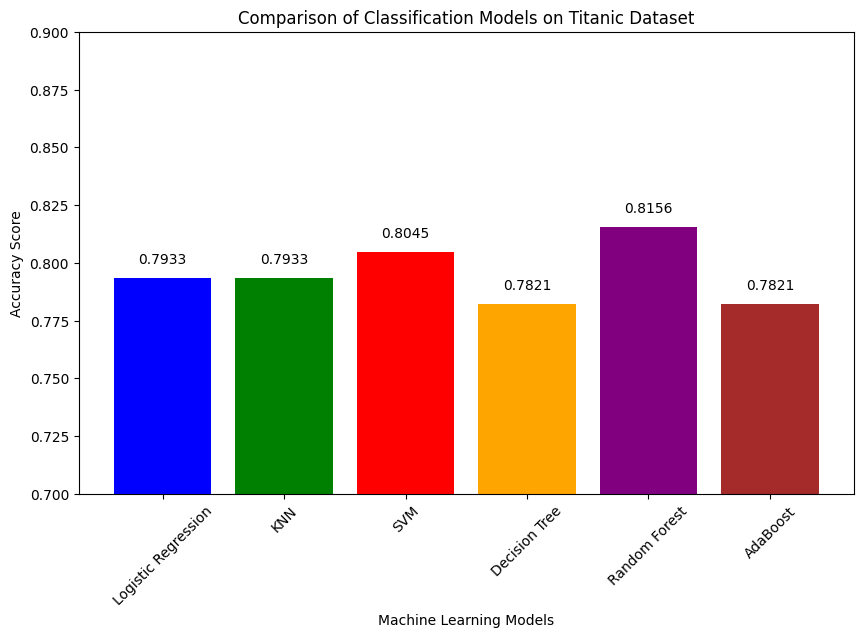

In [20]:
# 7- Final comparison of the models (مقایسه نهایی مدل ها)
# ===================================================
# 7-1- Accuracy bar chart (نمودار میله ای دقت مدل ها)
plt.figure(figsize=(10, 6))
bars = plt.bar(model_names, accuracies, color=['blue', 'green', 'red', 'orange', 'purple', 'brown'])
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy Score')
plt.title('Comparison of Classification Models on Titanic Dataset')
plt.ylim(0.7, 0.9)
plt.xticks(rotation=45)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.005, round(yval, 4), ha='center', va='bottom')

plt.show()

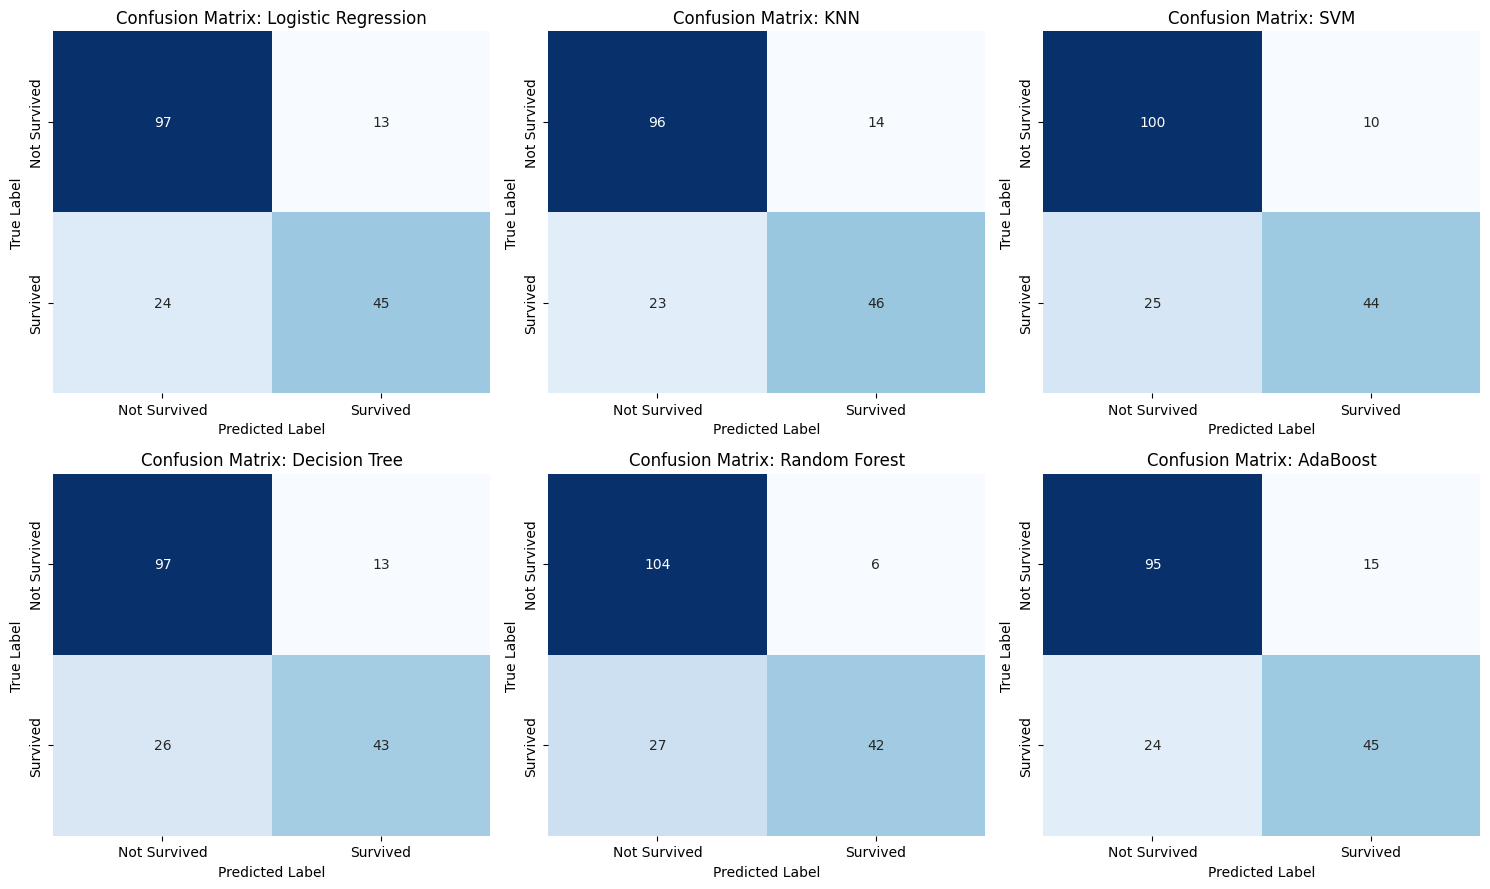

In [21]:
# 7-2- Confusion matrices of all models (ماتریس درهم ریختگی همه مدل ها)
models_data = [
    ('Logistic Regression', y_pred_lr, y_prob_lr),
    ('KNN', y_pred_knn, y_prob_knn),
    ('SVM', y_pred_svm, y_prob_svm),
    ('Decision Tree', y_pred_dt, y_prob_dt),
    ('Random Forest', y_pred_rf, y_prob_rf),
    ('AdaBoost', y_pred_ada, y_prob_ada)
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, preds, probs) in zip(axes.ravel(), models_data):
    sns.heatmap(confusion_matrix(y_test, preds), annot=True, fmt='d', cmap='Blues',
                xticklabels=target_names, yticklabels=target_names, cbar=False, ax=ax)
    ax.set_title(f'Confusion Matrix: {name}')
    ax.set_ylabel('True Label')
    ax.set_xlabel('Predicted Label')
plt.tight_layout()
plt.show()

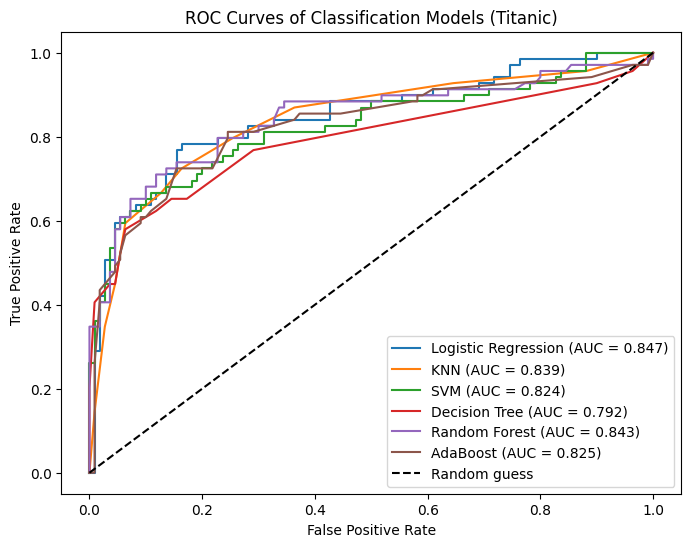

In [22]:
# 7-3- ROC curves (منحنی های ROC)
plt.figure(figsize=(8, 6))
for name, preds, probs in models_data:
    fpr, tpr, _ = roc_curve(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves of Classification Models (Titanic)')
plt.legend(loc='lower right')
plt.show()

In [23]:
# 7-4- Creating and sorting the results table (ساخت و مرتب سازی جدول نتایج)
metrics_list = []

for name, preds, probs in models_data:
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average='weighted')
    rec = recall_score(y_test, preds, average='weighted')
    f1 = f1_score(y_test, preds, average='weighted')
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_auc = auc(fpr, tpr)

    metrics_list.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'AUC': roc_auc
    })

res_df = pd.DataFrame(metrics_list)
res_df = res_df.sort_values(by='AUC', ascending=False).reset_index(drop=True)
res_df

,Model,Accuracy,Precision,Recall,F1-Score,AUC
0,Logistic Regression,0.793296,0.791711,0.793296,0.789266,0.847299
1,Random Forest,0.815642,0.825158,0.815642,0.807130,0.843478
2,KNN,0.793296,0.791282,0.793296,0.790147,0.838867
3,AdaBoost,0.782123,0.779693,0.782123,0.778804,0.825165
4,SVM,0.804469,0.805711,0.804469,0.798787,0.823715
5,Decision Tree,0.782123,0.780615,0.782123,0.776871,0.791765


In [24]:
# 7-5- Best model (بهترین مدل)
best_by_auc = res_df.loc[0, 'Model']
best_by_acc = res_df.loc[res_df['Accuracy'].idxmax(), 'Model']
print("Best model by AUC:", best_by_auc)
print("Best model by Accuracy:", best_by_acc)

Best model by AUC: Logistic Regression
Best model by Accuracy: Random Forest


## Conclusion (نتیجه گیری)

- **Random Forest** achieved the highest accuracy (about 0.82) on the test set.
- **Logistic Regression** achieved the highest AUC (about 0.85), meaning it ranks survivors vs. non-survivors slightly better overall.
- All models perform within a narrow range (accuracy 0.78 to 0.82), so on a small dataset like Titanic (891 rows) the differences between models are small. Results may change slightly with a different `random_state` or split.